# SynPAIN — Masking, Dataset Preparation, and PyTorch Training

**Purpose:** one resumable notebook for the SynPAIN experiment: locate the existing Google Drive project, obtain the dataset, create right-portrait crops, detect faces, create segmentation masks, prepare masked images, and train/evaluate a PyTorch classifier.

**Important:** run cells from top to bottom. Outputs are cached in Google Drive, so rerunning the notebook should reuse completed files rather than repeat the whole pipeline. A runtime reset loses installed packages and variables, but files saved in Drive remain.

**Research caution:** SynPAIN is synthetic. This notebook provides a technical pilot and baseline; it does not by itself establish generalization to real patients. A valid unseen-subject evaluation requires reliable subject IDs and subject-level splitting.

## 1. Mount Drive and locate the existing project
This searches for the project folder without assuming it is directly under `MyDrive`. It does not create a second project folder.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os, json, random, shutil, subprocess, sys, time, warnings
import numpy as np
import pandas as pd

MYDRIVE = Path("/content/drive/MyDrive")
PROJECT_NAME = "Facial Pain Assessment Research"

candidates = [p for p in MYDRIVE.rglob("*")
              if p.is_dir() and p.name.strip().casefold() == PROJECT_NAME.casefold()]

if not candidates:
    # Allow common spelling/capitalization variants while still avoiding a new project folder.
    candidates = [p for p in MYDRIVE.rglob("*")
                  if p.is_dir() and "facial pain" in p.name.casefold()
                  and "assessment" in p.name.casefold()]

if not candidates:
    raise FileNotFoundError(
        "Could not find the existing project folder in MyDrive. "
        "Open Drive and confirm its exact folder name and location, then rerun this cell."
    )

ROOT = candidates[0]
print("Using existing project folder:", ROOT)
print("Other matching folders:", [str(p) for p in candidates[1:]])

# Reuse existing folders; create only the standard subfolders if missing.
DIRS = {
    "dataset": ROOT / "02_Datasets" / "04_SynPAIN",
    "models": ROOT / "04_Implementation" / "models",
    "manifests": ROOT / "manifests",
    "crops": ROOT / "right_portrait_crops",
    "face_detection": ROOT / "face_detection",
    "masks": ROOT / "segmentation_masks",
    "experiments": ROOT / "05_Experiments" / "synpain_training",
    "results": ROOT / "06_Results" / "synpain_training",
    "logs": ROOT / "logs",
}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

for k, p in DIRS.items():
    print(f"{k:16s} -> {p}")

Mounted at /content/drive
Using existing project folder: /content/drive/MyDrive/Facial Pain Assessment Research
Other matching folders: []
dataset          -> /content/drive/MyDrive/Facial Pain Assessment Research/02_Datasets/04_SynPAIN
models           -> /content/drive/MyDrive/Facial Pain Assessment Research/04_Implementation/models
manifests        -> /content/drive/MyDrive/Facial Pain Assessment Research/manifests
crops            -> /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops
face_detection   -> /content/drive/MyDrive/Facial Pain Assessment Research/face_detection
masks            -> /content/drive/MyDrive/Facial Pain Assessment Research/segmentation_masks
experiments      -> /content/drive/MyDrive/Facial Pain Assessment Research/05_Experiments/synpain_training
results          -> /content/drive/MyDrive/Facial Pain Assessment Research/06_Results/synpain_training
logs             -> /content/drive/MyDrive/Facial Pain Assessment Research/logs


## 2. Check runtime and install only missing packages
This cell is intentionally separate. If the runtime resets, rerun it once. It does not reinstall packages that import successfully.

In [ ]:
import importlib.util

def ensure_import(import_name, pip_spec):
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing missing package: {pip_spec}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_spec])
    else:
        print(f"Already available: {import_name}")

ensure_import("huggingface_hub", "huggingface_hub")
ensure_import("cv2", "opencv-python-headless")
ensure_import("torch", "torch")
ensure_import("torchvision", "torchvision")
ensure_import("sklearn", "scikit-learn")
ensure_import("PIL", "Pillow")
ensure_import("mediapipe", "mediapipe")

import torch, torchvision, cv2
from PIL import Image
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("Note: CPU training is possible but slower. In Colab choose Runtime > Change runtime type > T4 GPU if available.")

Already available: huggingface_hub
Already available: cv2
Already available: torch
Already available: torchvision
Already available: sklearn
Already available: PIL
Installing missing package: mediapipe
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
OpenCV: 4.14.0
Device: cpu
Note: CPU training is possible but slower. In Colab choose Runtime > Change runtime type > T4 GPU if available.


## 3. Obtain SynPAIN files (reuse cache)
Downloads image files from the public Hugging Face repository only if the local image cache is incomplete. Existing images are not downloaded again. This can take time on the first run.

In [ ]:
from huggingface_hub import HfApi, hf_hub_download
from collections import Counter

REPO_ID = "TaatiTeam/SynPAIN"
RAW_DIR = DIRS["dataset"] / "raw_images"
RAW_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi()
repo_files = api.list_repo_files(repo_id=REPO_ID, repo_type="dataset")
image_paths = [f for f in repo_files if Path(f).suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
print("Image files listed by repository:", len(image_paths))
if not image_paths:
    raise RuntimeError("No image files were found in the SynPAIN repository listing.")

# Keep original repository-relative paths so each filename remains traceable.
downloaded = []
errors = []
for i, rel in enumerate(image_paths, 1):
    dest = RAW_DIR / rel
    if dest.exists() and dest.stat().st_size > 0:
        downloaded.append((rel, str(dest)))
        continue
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        src = hf_hub_download(repo_id=REPO_ID, repo_type="dataset", filename=rel)
        shutil.copy2(src, dest)
        downloaded.append((rel, str(dest)))
    except Exception as e:
        errors.append((rel, repr(e)))
    if i % 250 == 0:
        print(f"Checked {i}/{len(image_paths)} files; available={len(downloaded)}; errors={len(errors)}")

print("Available images:", len(downloaded))
print("Download errors:", len(errors))
if errors[:5]:
    print("First errors:", errors[:5])

# Persist a manifest so later cells use the same file inventory.
image_manifest_path = DIRS["manifests"] / "synpain_image_manifest.csv"
pd.DataFrame(downloaded, columns=["repo_path", "image_path"]).to_csv(image_manifest_path, index=False)
print("Saved:", image_manifest_path)
if len(downloaded) < 100:
    raise RuntimeError("Fewer than 100 images are available. Check the download errors before continuing.")

NameError: name 'DIRS' is not defined

## 4. Build labels and right-portrait crops
SynPAIN filenames encode Pain/NoPain in the expression field. This cell checks the filename patterns before processing and reuses already saved crops. It keeps the right half of each side-by-side image, as established during the pilot.

In [ ]:
image_manifest_path = DIRS["manifests"] / "synpain_image_manifest.csv"
img_df = pd.read_csv(image_manifest_path)

def infer_label(repo_path):
    stem = Path(repo_path).stem
    tokens = stem.replace("-", "_").split("_")
    low = [t.casefold() for t in tokens]
    if any(t in {"nopain", "no-pain", "no", "neutral"} for t in low):
        # Explicit NoPain token takes priority.
        if "nopain" in low or "no-pain" in low:
            return "NoPain"
    if "pain" in low:
        return "Pain"
    # Common filename form is [ID]_[expression]_[gender]_[age].jpg
    for t in low:
        if t == "nopain":
            return "NoPain"
        if t == "pain":
            return "Pain"
    return None

img_df["label"] = img_df["repo_path"].map(infer_label)
unlabelled = img_df["label"].isna().sum()
print("Files:", len(img_df), "| Unrecognized labels:", unlabelled)
if unlabelled:
    print(img_df.loc[img_df.label.isna(), "repo_path"].head(15).to_list())
    raise ValueError("Some filenames did not match Pain/NoPain labels. Inspect examples above before continuing.")

# Stable unique ID from original repository path.
img_df["sample_id"] = img_df["repo_path"].map(lambda x: Path(x).stem)
img_df["crop_path"] = img_df["sample_id"].map(lambda x: str(DIRS["crops"] / f"{x}_right.png"))

crop_errors = []
for row in img_df.itertuples(index=False):
    out = Path(row.crop_path)
    if out.exists() and out.stat().st_size > 0:
        continue
    try:
        with Image.open(row.image_path) as im:
            im = im.convert("RGB")
            w, h = im.size
            if w < 2 or h < 2:
                raise ValueError(f"Invalid image dimensions: {im.size}")
            crop = im.crop((w // 2, 0, w, h))
            crop.save(out, format="PNG")
    except Exception as e:
        crop_errors.append((row.repo_path, repr(e)))

img_df = img_df[[ "sample_id", "repo_path", "image_path", "label", "crop_path" ]]
img_df.to_csv(DIRS["manifests"] / "synpain_all_images_manifest.csv", index=False)
print("Label counts:")
print(img_df["label"].value_counts())
print("Crop errors:", len(crop_errors))
if crop_errors[:5]:
    print(crop_errors[:5])
print("Crops available:", sum(Path(p).exists() for p in img_df.crop_path))

Files: 5395 | Unrecognized labels: 0
Label counts:
label
Pain      2756
NoPain    2639
Name: count, dtype: int64
Crop errors: 0
Crops available: 5395


## 5. Face detection (cached)
Detects one face in each crop using MediaPipe. If a detection CSV already exists and contains successful paths, it is reused. The cell records failures rather than silently treating them as valid samples.

In [ ]:
import mediapipe as mp

FACE_CSV = DIRS["face_detection"] / "synpain_face_detection_all.csv"
manifest_csv = DIRS["manifests"] / "synpain_all_images_manifest.csv"
img_df = pd.read_csv(manifest_csv)

if FACE_CSV.exists():
    face_df = pd.read_csv(FACE_CSV)
    cached_paths = set(face_df["crop_path"].astype(str)) if "crop_path" in face_df.columns else set()
    current_paths = set(img_df["crop_path"].astype(str))
    if len(cached_paths) == len(current_paths) and cached_paths == current_paths:
        print("Reusing cached face-detection CSV:", FACE_CSV)
    else:
        print("Cached face-detection inventory differs; rebuilding detections.")
        face_df = None
else:
    face_df = None

if face_df is None:
    BaseOptions = mp.tasks.BaseOptions
    FaceDetector = mp.tasks.vision.FaceDetector
    FaceDetectorOptions = mp.tasks.vision.FaceDetectorOptions
    VisionRunningMode = mp.tasks.vision.RunningMode

    model_path = DIRS["models"] / "blaze_face_short_range.tflite"
    if not model_path.exists():
        import urllib.request
        model_path.parent.mkdir(parents=True, exist_ok=True)
        model_url = "https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite"
        urllib.request.urlretrieve(model_url, model_path)

    options = FaceDetectorOptions(
        base_options=BaseOptions(model_asset_path=str(model_path)),
        running_mode=VisionRunningMode.IMAGE,
        min_detection_confidence=0.5,
    )
    rows = []
    with FaceDetector.create_from_options(options) as detector:
        for i, row in enumerate(img_df.itertuples(index=False), 1):
            rec = {"sample_id": row.sample_id, "repo_path": row.repo_path,
                   "label": row.label, "crop_path": row.crop_path,
                   "detection_status": "failed", "face_count": 0,
                   "x": np.nan, "y": np.nan, "width": np.nan, "height": np.nan,
                   "confidence": np.nan, "error": ""}
            try:
                arr = np.asarray(Image.open(row.crop_path).convert("RGB"))
                mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=arr)
                result = detector.detect(mp_image)
                detections = result.detections or []
                rec["face_count"] = len(detections)
                if len(detections) == 1:
                    bb = detections[0].bounding_box
                    H, W = arr.shape[:2]
                    x1 = max(0, bb.origin_x); y1 = max(0, bb.origin_y)
                    x2 = min(W, bb.origin_x + bb.width); y2 = min(H, bb.origin_y + bb.height)
                    rec.update({"detection_status": "success", "x": x1, "y": y1,
                                "width": max(0, x2-x1), "height": max(0, y2-y1),
                                "confidence": float(detections[0].categories[0].score)
                                if detections[0].categories else np.nan})
                else:
                    rec["error"] = f"Expected one face, found {len(detections)}"
            except Exception as e:
                rec["error"] = repr(e)
            rows.append(rec)
            if i % 250 == 0:
                print(f"Detected {i}/{len(img_df)}")
    face_df = pd.DataFrame(rows)
    face_df.to_csv(FACE_CSV, index=False)

print("Detection status:")
print(face_df["detection_status"].value_counts(dropna=False))
print("Face counts:")
print(face_df["face_count"].value_counts(dropna=False).sort_index())
print("Saved:", FACE_CSV)

Detected 250/5395
Detected 500/5395
Detected 750/5395
Detected 1000/5395
Detected 1250/5395
Detected 1500/5395
Detected 1750/5395
Detected 2000/5395
Detected 2250/5395
Detected 2500/5395
Detected 2750/5395
Detected 3000/5395
Detected 3250/5395
Detected 3500/5395
Detected 3750/5395
Detected 4000/5395
Detected 4250/5395
Detected 4500/5395
Detected 4750/5395
Detected 5000/5395
Detected 5250/5395
Detection status:
detection_status
success    5353
failed       42
Name: count, dtype: int64
Face counts:
face_count
0       1
1    5353
2      41
Name: count, dtype: int64
Saved: /content/drive/MyDrive/Facial Pain Assessment Research/face_detection/synpain_face_detection_all.csv


## 6. Install/restore SAM2 only if needed
SAM2 is used for segmentation masks. The checkpoint is stored in Drive and reused. If the install fails, stop here and share the full error instead of rerunning earlier cells.

In [ ]:


from pathlib import Path
import importlib.util
import subprocess
import sys
import torch

# 1. Mount Google Drive if it is not already mounted.
from google.colab import drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# 2. Locate the existing project folder.
MYDRIVE = Path("/content/drive/MyDrive")
matches = [
    p for p in MYDRIVE.iterdir()
    if p.is_dir()
    and "facial pain" in p.name.lower()
    and "research" in p.name.lower()
]

if not matches:
    raise FileNotFoundError(
        "Project folder not found directly in MyDrive. "
        "Check the exact folder name and location in Google Drive."
    )

ROOT = matches[0]
SAM_CKPT = ROOT / "04_Implementation" / "models" / "sam2_hiera_tiny.pt"

print("Project:", ROOT)
print("Checkpoint exists:", SAM_CKPT.exists())

if not SAM_CKPT.exists():
    raise FileNotFoundError(
        f"SAM2 checkpoint is missing: {SAM_CKPT}\n"
        "Check the existing models folder before downloading anything."
    )

# 3. Install SAM2 only if missing.
if importlib.util.find_spec("sam2") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/facebookresearch/sam2.git"
    ])

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# 4. Initialize SAM2 with the package-relative config.
SAM_CONFIG = "configs/sam2/sam2_hiera_t.yaml"
device = "cuda" if torch.cuda.is_available() else "cpu"

sam_model = build_sam2(
    SAM_CONFIG,
    str(SAM_CKPT),
    device=device
)
sam_predictor = SAM2ImagePredictor(sam_model)

print("SAM2 initialized successfully.")
print("Device:", device)



Mounted at /content/drive
Project: /content/drive/MyDrive/Facial Pain Assessment Research
Checkpoint exists: True
SAM2 initialized successfully.
Device: cpu


## 7. Create masks with face-box prompts (resume-safe)
Uses detected face boxes as SAM2 prompts. Masks with implausible coverage are flagged for review. **Do not assume every generated mask is correct**—review the sample grid before trusting masks for training.

In [ ]:
from pathlib import Path
import torch
import importlib.util
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
SAM_CKPT = ROOT / "04_Implementation" / "models" / "sam2_hiera_tiny.pt"

assert SAM_CKPT.exists(), f"SAM2 checkpoint not found: {SAM_CKPT}"

if importlib.util.find_spec("sam2") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/facebookresearch/sam2.git"
    ])

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

device = "cuda" if torch.cuda.is_available() else "cpu"

sam_model = build_sam2(
    "configs/sam2/sam2_hiera_t.yaml",
    str(SAM_CKPT),
    device=device
)
sam_predictor = SAM2ImagePredictor(sam_model)

print("SAM2 ready:", device)
print("Predictor exists:", "sam_predictor" in globals())

SAM2 ready: cpu
Predictor exists: True


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")

FACE_CSV = ROOT / "face_detection" / "synpain_face_detection_all.csv"
if not FACE_CSV.exists():
    FACE_CSV = ROOT / "face_detection" / "synpain_pilot_face_detection.csv"

MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"
MASK_DIR.mkdir(parents=True, exist_ok=True)

MASK_CSV = ROOT / "manifests" / "synpain_segmentation_manifest.csv"

face_df = pd.read_csv(FACE_CSV)
mask_df = pd.read_csv(MASK_CSV) if MASK_CSV.exists() else pd.DataFrame()

print("Face file:", FACE_CSV)
print("Face CSV columns:", face_df.columns.tolist())
print("Existing mask records:", len(mask_df))
print(face_df.head(3).to_string(index=False))

Face file: /content/drive/MyDrive/Facial Pain Assessment Research/face_detection/synpain_face_detection_all.csv
Face CSV columns: ['sample_id', 'repo_path', 'label', 'crop_path', 'detection_status', 'face_count', 'x', 'y', 'width', 'height', 'confidence', 'error']
Existing mask records: 5313
                  sample_id                                      repo_path  label                                                                                                         crop_path detection_status  face_count     x     y  width  height  confidence error
1000012790_NoPain_man_Young SynPain/Images/1000012790_NoPain_man_Young.jpg NoPain /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000012790_NoPain_man_Young_right.png          success           1 196.0 162.0  256.0   256.0    0.898317   NaN
1000013970_NoPain_man_Young SynPain/Images/1000013970_NoPain_man_Young.jpg NoPain /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/100001397

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import traceback

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"
MASK_DIR.mkdir(parents=True, exist_ok=True)

FACE_CSV = ROOT / "face_detection" / "synpain_face_detection_all.csv"
MASK_CSV = ROOT / "manifests" / "synpain_segmentation_manifest.csv"

face_df = pd.read_csv(FACE_CSV)
mask_df = pd.read_csv(MASK_CSV)

# Select 10 successful detections whose masks do not exist yet
valid = face_df[
    (face_df["detection_status"] == "success") &
    (face_df["face_count"] == 1)
].copy()

valid = valid[valid["crop_path"].map(lambda p: Path(p).exists())]
valid = valid[
    ~valid["sample_id"].isin(
        mask_df.loc[mask_df["mask_status"] == "success", "sample_id"]
    )
]

test_df = valid.head(10)
print("Images selected for test:", len(test_df))

results = []

for _, row in test_df.iterrows():
    try:
        image = Image.open(row["crop_path"]).convert("RGB")
        image_np = np.array(image)
        h, w = image_np.shape[:2]

        # Expand the detected face box slightly
        x1 = max(0, int(row["x"] - 0.10 * row["width"]))
        y1 = max(0, int(row["y"] - 0.10 * row["height"]))
        x2 = min(w - 1, int(row["x"] + 1.10 * row["width"]))
        y2 = min(h - 1, int(row["y"] + 1.10 * row["height"]))

        sam_predictor.set_image(image_np)
        masks, scores, _ = sam_predictor.predict(
            box=np.array([x1, y1, x2, y2]),
            multimask_output=False
        )

        mask = masks[0].astype(bool)
        coverage = float(mask.mean())

        out_path = MASK_DIR / f"{row['sample_id']}_mask.png"
        Image.fromarray((mask * 255).astype(np.uint8)).save(out_path)

        results.append({
            "sample_id": row["sample_id"],
            "label": row["label"],
            "mask_path": str(out_path),
            "mask_status": "success",
            "mask_coverage": coverage,
            "error": ""
        })

        print(
            f"OK: {row['sample_id']} | "
            f"coverage={coverage:.3f} | score={float(scores[0]):.3f}"
        )

    except Exception as e:
        results.append({
            "sample_id": row["sample_id"],
            "label": row["label"],
            "mask_path": "",
            "mask_status": "failed",
            "mask_coverage": np.nan,
            "error": repr(e)
        })
        print("FAILED:", row["sample_id"], repr(e))

print("\nSuccessful test masks:", sum(r["mask_status"] == "success" for r in results))
print("Failed test masks:", sum(r["mask_status"] == "failed" for r in results))
print("Mask files now in folder:", len(list(MASK_DIR.glob("*_mask.png"))))

Images selected for test: 10
OK: 1000012790_NoPain_man_Young | coverage=0.167 | score=0.937
OK: 1000013970_NoPain_man_Young | coverage=0.166 | score=0.889
OK: 1000016120_NoPain_man_Young | coverage=0.090 | score=0.883
OK: 1000016140_NoPain_man_Young | coverage=0.138 | score=0.931
OK: 1000017500_NoPain_man_Young | coverage=0.129 | score=0.938
OK: 1000019760_NoPain_man_Young | coverage=0.127 | score=0.893
OK: 1000020260_NoPain_man_Young | coverage=0.141 | score=0.897
OK: 1000020490_NoPain_man_Young | coverage=0.276 | score=0.927
OK: 1000020580_NoPain_man_Young | coverage=0.119 | score=0.911
OK: 1000020600_NoPain_man_Young | coverage=0.154 | score=0.904

Successful test masks: 10
Failed test masks: 0
Mask files now in folder: 10


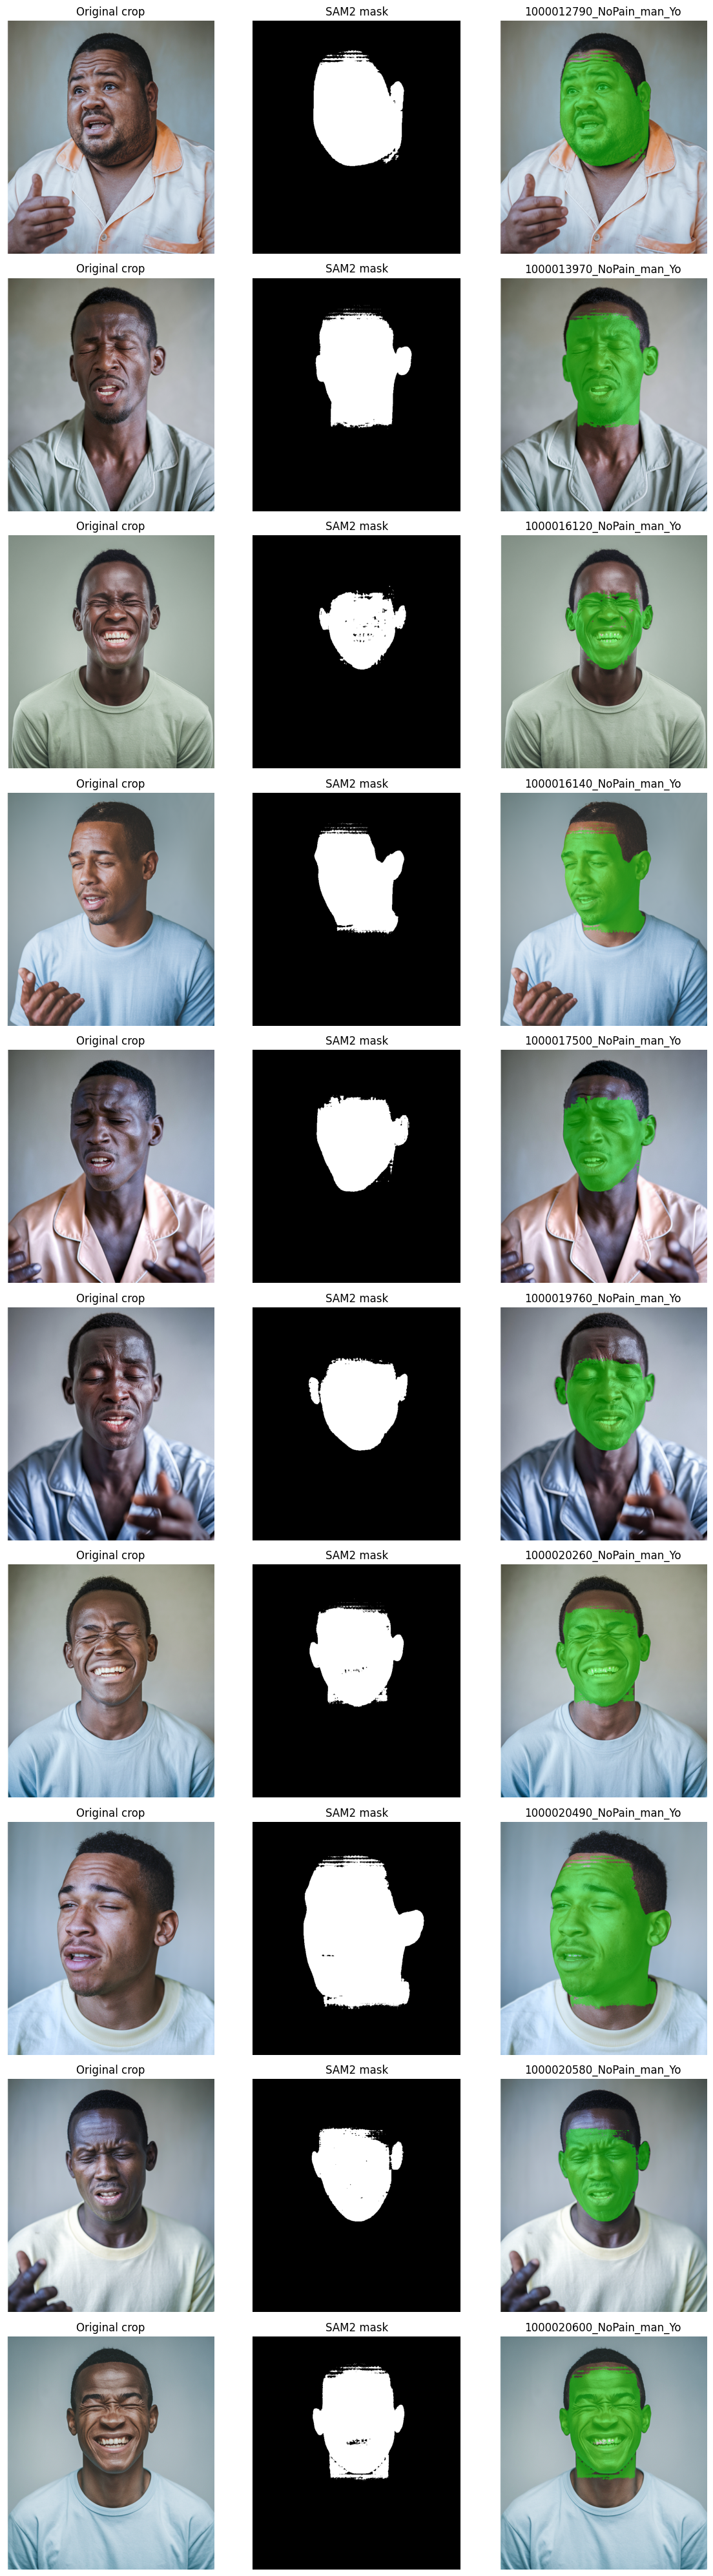

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"
FACE_CSV = ROOT / "face_detection" / "synpain_face_detection_all.csv"

face_df = pd.read_csv(FACE_CSV)
mask_files = sorted(MASK_DIR.glob("*_mask.png"))[:10]

fig, axes = plt.subplots(len(mask_files), 3, figsize=(12, 4 * len(mask_files)))

for i, mask_path in enumerate(mask_files):
    sample_id = mask_path.name.replace("_mask.png", "")
    row = face_df[face_df["sample_id"] == sample_id].iloc[0]

    image = np.array(Image.open(row["crop_path"]).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L")) > 0

    overlay = image.copy()
    overlay[mask] = (
        0.55 * overlay[mask] + 0.45 * np.array([0, 255, 0])
    ).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original crop")
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("SAM2 mask")
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(sample_id[:24])

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
FACE_CSV = ROOT / "face_detection" / "synpain_face_detection_all.csv"
MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"

face_df = pd.read_csv(FACE_CSV)
test_files = sorted(MASK_DIR.glob("*_mask.png"))[:10]

for mask_path in test_files:
    sample_id = mask_path.name.replace("_mask.png", "")
    row = face_df[face_df["sample_id"] == sample_id].iloc[0]

    image = Image.open(row["crop_path"]).convert("RGB")
    image_np = np.array(image)
    h, w = image_np.shape[:2]

    # Expand further above the face to include the forehead
    x1 = max(0, int(row["x"] - 0.10 * row["width"]))
    y1 = max(0, int(row["y"] - 0.25 * row["height"]))
    x2 = min(w - 1, int(row["x"] + 1.10 * row["width"]))
    y2 = min(h - 1, int(row["y"] + 1.10 * row["height"]))

    sam_predictor.set_image(image_np)
    masks, scores, _ = sam_predictor.predict(
        box=np.array([x1, y1, x2, y2]),
        multimask_output=False
    )

    mask = masks[0].astype(bool)
    Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)

    print(f"{sample_id}: coverage={mask.mean():.3f}")

print("Updated the 10 test masks. Inspect them again before proceeding.")

1000012790_NoPain_man_Young: coverage=0.171
1000013970_NoPain_man_Young: coverage=0.156
1000016120_NoPain_man_Young: coverage=0.135
1000016140_NoPain_man_Young: coverage=0.136
1000017500_NoPain_man_Young: coverage=0.148
1000019760_NoPain_man_Young: coverage=0.126
1000020260_NoPain_man_Young: coverage=0.162
1000020490_NoPain_man_Young: coverage=0.258
1000020580_NoPain_man_Young: coverage=0.153
1000020600_NoPain_man_Young: coverage=0.147
Updated the 10 test masks. Inspect them again before proceeding.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
FACE_CSV = ROOT / "face_detection" / "synpain_face_detection_all.csv"
MASK_CSV = ROOT / "manifests" / "synpain_segmentation_manifest.csv"
MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"

MASK_DIR.mkdir(parents=True, exist_ok=True)

face_df = pd.read_csv(FACE_CSV)
mask_df = pd.read_csv(MASK_CSV)

# Keep prior records; retry failed records rather than trusting them
valid = face_df[
    (face_df["detection_status"] == "success") &
    (face_df["face_count"] == 1)
].copy()

valid = valid[valid["crop_path"].map(lambda p: Path(p).exists())]

# Only skip records whose mask file really exists and was saved successfully
completed_ids = set(
    mask_df[
        (mask_df["mask_status"] == "success") &
        (mask_df["mask_path"].map(
            lambda p: isinstance(p, str) and Path(p).exists()
        ))
    ]["sample_id"].astype(str)
)

todo = valid[~valid["sample_id"].astype(str).isin(completed_ids)].copy()

print("Valid detected faces:", len(valid))
print("Masks already completed:", len(completed_ids))
print("Images remaining:", len(todo))

# Process in small batches; manifest is saved after each batch
BATCH_SIZE = 25
new_records = []

for start in range(0, len(todo), BATCH_SIZE):
    batch = todo.iloc[start:start + BATCH_SIZE]

    for _, row in batch.iterrows():
        sample_id = str(row["sample_id"])
        out_path = MASK_DIR / f"{sample_id}_mask.png"

        try:
            image = Image.open(row["crop_path"]).convert("RGB")
            image_np = np.array(image)
            h, w = image_np.shape[:2]

            # Expanded box: extra room above the face for the forehead
            x1 = max(0, int(row["x"] - 0.10 * row["width"]))
            y1 = max(0, int(row["y"] - 0.25 * row["height"]))
            x2 = min(w - 1, int(row["x"] + 1.10 * row["width"]))
            y2 = min(h - 1, int(row["y"] + 1.10 * row["height"]))

            sam_predictor.set_image(image_np)
            masks, scores, _ = sam_predictor.predict(
                box=np.array([x1, y1, x2, y2]),
                multimask_output=False
            )

            mask = masks[0].astype(bool)
            coverage = float(mask.mean())
            Image.fromarray((mask * 255).astype(np.uint8)).save(out_path)

            new_records.append({
                "sample_id": sample_id,
                "label": row["label"],
                "crop_path": str(row["crop_path"]),
                "mask_path": str(out_path),
                "mask_status": "success",
                "mask_coverage": coverage,
                "error": ""
            })

        except Exception as e:
            new_records.append({
                "sample_id": sample_id,
                "label": row["label"],
                "crop_path": str(row["crop_path"]),
                "mask_path": str(out_path),
                "mask_status": "failed",
                "mask_coverage": np.nan,
                "error": repr(e)
            })

    # Merge and save after each batch so progress is preserved
    if new_records:
        updated = pd.DataFrame(new_records)
        mask_df = pd.concat(
            [mask_df[~mask_df["sample_id"].isin(updated["sample_id"])],
             updated],
            ignore_index=True
        )
        mask_df.to_csv(MASK_CSV, index=False)
        new_records = []

    print(
        f"Processed {min(start + BATCH_SIZE, len(todo))}/{len(todo)} "
        f"remaining images; manifest saved."
    )

print("\nSegmentation batch run finished.")
print("Manifest:", MASK_CSV)
print(mask_df["mask_status"].value_counts(dropna=False).to_dict())

Valid detected faces: 5353
Masks already completed: 0
Images remaining: 5353
Processed 25/5353 remaining images; manifest saved.
Processed 50/5353 remaining images; manifest saved.
Processed 75/5353 remaining images; manifest saved.
Processed 100/5353 remaining images; manifest saved.
Processed 125/5353 remaining images; manifest saved.
Processed 150/5353 remaining images; manifest saved.
Processed 175/5353 remaining images; manifest saved.
Processed 200/5353 remaining images; manifest saved.
Processed 225/5353 remaining images; manifest saved.
Processed 250/5353 remaining images; manifest saved.
Processed 275/5353 remaining images; manifest saved.
Processed 300/5353 remaining images; manifest saved.
Processed 325/5353 remaining images; manifest saved.
Processed 350/5353 remaining images; manifest saved.
Processed 375/5353 remaining images; manifest saved.
Processed 400/5353 remaining images; manifest saved.
Processed 425/5353 remaining images; manifest saved.
Processed 450/5353 remain

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
manifest = root / "manifests" / "synpain_segmentation_manifest.csv"
mask_dir = root / "segmentation_masks" / "synpain_sam2_box"

df = pd.read_csv(manifest)

print("Successful records:", (df["mask_status"] == "success").sum())
print("Failed records:", (df["mask_status"] == "failed").sum())
print("Mask files actually saved:", len(list(mask_dir.glob("*_mask.png"))))
print("Face crops available:", len(list(
    (root / "right_portrait_crops").glob("*.png")
)))

Successful records: 2450
Failed records: 2863
Mask files actually saved: 2464
Face crops available: 5355


In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Facial Pain Assessment Research")

manifest_path = root / "manifests" / "synpain_all_images_manifest.csv"
df = pd.read_csv(manifest_path)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print(df.head(3).to_string(index=False))

Rows: 5395
Columns: ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path']
                  sample_id                                      repo_path                                                                                                                              image_path  label                                                                                                         crop_path
1000012790_NoPain_man_Young SynPain/Images/1000012790_NoPain_man_Young.jpg /content/drive/MyDrive/Facial Pain Assessment Research/02_Datasets/04_SynPAIN/raw_images/SynPain/Images/1000012790_NoPain_man_Young.jpg NoPain /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000012790_NoPain_man_Young_right.png
1000013970_NoPain_man_Young SynPain/Images/1000013970_NoPain_man_Young.jpg /content/drive/MyDrive/Facial Pain Assessment Research/02_Datasets/04_SynPAIN/raw_images/SynPain/Images/1000013970_NoPain_man_Young.jpg NoPain /content/drive/MyDrive/Facial Pain 

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
manifest_path = ROOT / "manifests" / "synpain_all_images_manifest.csv"

df = pd.read_csv(manifest_path)

# Extract the first filename component
df["filename_id"] = df["sample_id"].astype(str).str.split("_").str[0]

print("Total manifest rows:", len(df))
print("\nLabel counts:")
print(df["label"].value_counts(dropna=False))

print("\nUnique filename IDs:", df["filename_id"].nunique())
print("Filename IDs appearing more than once:",
      (df["filename_id"].value_counts() > 1).sum())

print("\nExamples of IDs with multiple records:")
print(
    df[df["filename_id"].duplicated(keep=False)]
    [["sample_id", "label", "filename_id"]]
    .head(10)
    .to_string(index=False)
)

print("\nExisting face crops:",
      df["crop_path"].map(lambda p: Path(p).is_file()).sum())

print("\nFilename examples:")
print(df["sample_id"].head(10).to_list())

Total manifest rows: 5395

Label counts:
label
Pain      2756
NoPain    2639
Name: count, dtype: int64

Unique filename IDs: 5355
Filename IDs appearing more than once: 40

Examples of IDs with multiple records:
                  sample_id  label filename_id
1000026870_NoPain_man_Young NoPain  1000026870
1000124840_NoPain_man_Young NoPain  1000124840
1000235030_NoPain_man_Young NoPain  1000235030
1000352210_NoPain_man_Young NoPain  1000352210
1000445970_NoPain_man_Young NoPain  1000445970
  1001015290_NoPain_man_Old NoPain  1001015290
  1001120000_NoPain_man_Old NoPain  1001120000
  1001242590_NoPain_man_Old NoPain  1001242590
  1001334160_NoPain_man_Old NoPain  1001334160
  1001423400_NoPain_man_Old NoPain  1001423400

Existing face crops: 5395

Filename examples:
['1000012790_NoPain_man_Young', '1000013970_NoPain_man_Young', '1000016120_NoPain_man_Young', '1000016140_NoPain_man_Young', '1000017500_NoPain_man_Young', '1000019760_NoPain_man_Young', '1000020260_NoPain_man_Young', '10000

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
df = pd.read_csv(ROOT / "manifests" / "synpain_all_images_manifest.csv")

df["filename_id"] = df["sample_id"].astype(str).str.split("_").str[0]

# Show all repeated IDs and their associated records
counts = df["filename_id"].value_counts()
repeated_ids = counts[counts > 1].index

duplicates = (
    df[df["filename_id"].isin(repeated_ids)]
    .sort_values("filename_id")
    [["sample_id", "repo_path", "label", "crop_path", "filename_id"]]
)

print("Repeated IDs:", len(repeated_ids))
print("Rows belonging to repeated IDs:", len(duplicates))
print(duplicates.head(30).to_string(index=False))

print("\nRepeated IDs with different labels:")
label_counts = df.groupby("filename_id")["label"].nunique()
print((label_counts > 1).sum())

Repeated IDs: 40
Rows belonging to repeated IDs: 80
                    sample_id                                        repo_path  label                                                                                                           crop_path filename_id
  1000026870_NoPain_man_Young   SynPain/Images/1000026870_NoPain_man_Young.jpg NoPain   /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000026870_NoPain_man_Young_right.png  1000026870
  1000026870_NoPain_man_Young   SynPain/Videos/1000026870_NoPain_man_Young.jpg NoPain   /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000026870_NoPain_man_Young_right.png  1000026870
  1000124840_NoPain_man_Young   SynPain/Images/1000124840_NoPain_man_Young.jpg NoPain   /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000124840_NoPain_man_Young_right.png  1000124840
  1000124840_NoPain_man_Young   SynPain/Videos/1000124840_NoPain_man_Young.jpg NoPain   /con

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")

INPUT = ROOT / "manifests" / "synpain_all_images_manifest.csv"
OUTPUT = ROOT / "manifests" / "synpain_unique_crops_manifest.csv"

df = pd.read_csv(INPUT)

# Keep one row per crop; the repeated Images/Videos entries share the same crop
before = len(df)
df = df.drop_duplicates(subset=["crop_path"], keep="first").copy()

# Keep only rows whose crop file actually exists
df = df[df["crop_path"].map(lambda p: Path(p).is_file())].copy()

df.to_csv(OUTPUT, index=False)

print("Original rows:", before)
print("Unique existing crops:", len(df))
print("\nLabels:")
print(df["label"].value_counts())
print("\nSaved clean manifest to:", OUTPUT)
print("\nDuplicate crop paths remaining:", df["crop_path"].duplicated().sum())

Original rows: 5395
Unique existing crops: 5355

Labels:
label
Pain      2736
NoPain    2619
Name: count, dtype: int64

Saved clean manifest to: /content/drive/MyDrive/Facial Pain Assessment Research/manifests/synpain_unique_crops_manifest.csv

Duplicate crop paths remaining: 0


In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
INPUT = ROOT / "manifests" / "synpain_unique_crops_manifest.csv"
OUTPUT = ROOT / "manifests"

df = pd.read_csv(INPUT)
df["filename_id"] = df["sample_id"].astype(str).str.split("_").str[0]

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(
    split1.split(df, df["label"], groups=df["filename_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: divide temporary data equally into validation and test
split2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(
    split2.split(temp_df, temp_df["label"], groups=temp_df["filename_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Save split manifests
train_df.to_csv(OUTPUT / "train_manifest.csv", index=False)
val_df.to_csv(OUTPUT / "validation_manifest.csv", index=False)
test_df.to_csv(OUTPUT / "test_manifest.csv", index=False)

print("Split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_ids = set(train_df["filename_id"])
val_ids = set(val_df["filename_id"])
test_ids = set(test_df["filename_id"])

print("\nFilename-ID overlap checks:")
print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

print("\nLabel counts by split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}:\n{part['label'].value_counts()}")

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

print("\nSaved all three split manifests successfully.")

Split sizes:
Train: 3748
Validation: 803
Test: 804

Filename-ID overlap checks:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Label counts by split:

Train:
label
Pain      1942
NoPain    1806
Name: count, dtype: int64

Validation:
label
Pain      416
NoPain    387
Name: count, dtype: int64

Test:
label
NoPain    426
Pain      378
Name: count, dtype: int64

Saved all three split manifests successfully.


In [ ]:
from pathlib import Path
import pandas as pd
import torch
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
MANIFESTS = ROOT / "manifests"

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU — we will keep training lightweight.")

for filename in [
    "train_manifest.csv",
    "validation_manifest.csv",
    "test_manifest.csv"
]:
    path = MANIFESTS / filename
    assert path.exists(), f"Missing file: {filename}"
    df = pd.read_csv(path)
    print(f"{filename}: {len(df)} rows; columns = {list(df.columns)}")

train = pd.read_csv(MANIFESTS / "train_manifest.csv")
sample_path = Path(train.iloc[0]["crop_path"])

assert sample_path.exists(), f"Image not found: {sample_path}"

with Image.open(sample_path) as img:
    print("Sample image size:", img.size)
    print("Sample image mode:", img.mode)

print("\nEnvironment and data checks passed.")

GPU available: False
Using CPU — we will keep training lightweight.
train_manifest.csv: 3748 rows; columns = ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
validation_manifest.csv: 803 rows; columns = ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
test_manifest.csv: 804 rows; columns = ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
Sample image size: (656, 736)
Sample image mode: RGB

Environment and data checks passed.


In [ ]:
import torch
import torchvision
from torchvision import transforms
from PIL import Image
import time

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Small, consistent input size for CPU training
IMAGE_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 3

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train = pd.read_csv(MANIFESTS / "train_manifest.csv")
sample = Image.open(train.iloc[0]["crop_path"]).convert("RGB")
tensor = transform(sample)

print("Transformed image shape:", tuple(tensor.shape))
print("Batch size:", BATCH_SIZE)
print("Initial epoch budget:", EPOCHS)
print("CPU training setup ready.")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Transformed image shape: (3, 128, 128)
Batch size: 16
Initial epoch budget: 3
CPU training setup ready.


In [ ]:
from pathlib import Path
import pandas as pd

# Rebuild paths without repeating the download or SAM2 setup
ROOT = Path(ROOT)

MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"
MASK_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_DIR = ROOT / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

MASK_CSV = MANIFEST_DIR / "synpain_segmentation_manifest.csv"

# Locate an existing face-detection CSV; prefer the full dataset if available
candidates = [
    ROOT / "face_detection" / "synpain_face_detection_all.csv",
    ROOT / "face_detection" / "synpain_pilot_face_detection.csv",
]

FACE_CSV = next((p for p in candidates if p.exists()), None)

if FACE_CSV is None:
    raise FileNotFoundError(
        "No existing face-detection CSV was found. "
        "Check the face_detection folder in your project Drive."
    )

print("Project:", ROOT)
print("Face-detection file:", FACE_CSV)
print("Mask output folder:", MASK_DIR)
print("SAM2 predictor available:", "sam_predictor" in globals())

assert "sam_predictor" in globals(), (
    "SAM2 predictor is missing. Run the corrected Cell 6 first."
)

face_df = pd.read_csv(FACE_CSV)

print("Rows in face-detection file:", len(face_df))
print("Columns:", face_df.columns.tolist())
print(face_df.head(3).to_string(index=False))

Project: /content/drive/MyDrive/Facial Pain Assessment Research
Face-detection file: /content/drive/MyDrive/Facial Pain Assessment Research/face_detection/synpain_face_detection_all.csv
Mask output folder: /content/drive/MyDrive/Facial Pain Assessment Research/segmentation_masks/synpain_sam2_box
SAM2 predictor available: True
Rows in face-detection file: 5395
Columns: ['sample_id', 'repo_path', 'label', 'crop_path', 'detection_status', 'face_count', 'x', 'y', 'width', 'height', 'confidence', 'error']
                  sample_id                                      repo_path  label                                                                                                         crop_path detection_status  face_count     x     y  width  height  confidence error
1000012790_NoPain_man_Young SynPain/Images/1000012790_NoPain_man_Young.jpg NoPain /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000012790_NoPain_man_Young_right.png          success           1

## 8. Visual quality check (required before training)
Review a small grid. If masks include hair/background or miss major facial regions, stop and improve segmentation prompts before training.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
from pathlib import Path

MASK_CSV = Path(
    "/content/drive/MyDrive/Facial Pain Assessment Research/manifests/synpain_segmentation_manifest.csv"
)

print("Manifest exists:", MASK_CSV.exists())

Manifest exists: False


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Google Drive mounted:", base.exists())

project = base / "Facial Pain Assessment Research"

if project.exists():
    print("\nProject folders:")
    for item in project.iterdir():
        print(item.name)

    print("\nSegmentation manifests found:")
    for item in project.rglob("*segmentation*manifest*.csv"):
        print(item)
else:
    print("Project folder not found.")

Google Drive mounted: False
Project folder not found.


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")
MANIFESTS = ROOT / "manifests"

print("Project folder exists:", ROOT.exists())

for name in [
    "train_manifest.csv",
    "validation_manifest.csv",
    "test_manifest.csv"
]:
    path = MANIFESTS / name
    print(name, "—", "Found" if path.exists() else "Not found")

Project folder exists: True
train_manifest.csv — Found
validation_manifest.csv — Found
test_manifest.csv — Found


In [ ]:
import pandas as pd
import torch
from PIL import Image
from pathlib import Path

train_df = pd.read_csv(MANIFESTS / "train_manifest.csv")
val_df = pd.read_csv(MANIFESTS / "validation_manifest.csv")
test_df = pd.read_csv(MANIFESTS / "test_manifest.csv")

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

sample = Image.open(train_df.iloc[0]["crop_path"]).convert("RGB")
print("Sample image:", sample.size)
print("Environment check complete.")

PyTorch: 2.14.1+cpu
GPU available: False
Training images: 3748
Validation images: 803
Testing images: 804
Sample image: (656, 736)
Environment check complete.


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Keep CPU usage manageable
torch.set_num_threads(2)
torch.manual_seed(42)
np.random.seed(42)

IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 3

# Load manifests
train_df = pd.read_csv(MANIFESTS / "train_manifest.csv")
val_df = pd.read_csv(MANIFESTS / "validation_manifest.csv")
test_df = pd.read_csv(MANIFESTS / "test_manifest.csv")

# Convert images into small arrays for faster CPU training
def load_images(df):
    images = []
    labels = []

    for _, row in df.iterrows():
        img = Image.open(row["crop_path"]).convert("RGB")
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE))
        images.append(np.asarray(img, dtype=np.uint8))
        labels.append(1 if row["label"] == "Pain" else 0)

    return (
        torch.tensor(np.array(images)).permute(0, 3, 1, 2),
        torch.tensor(labels, dtype=torch.long)
    )

print("Loading images...")
X_train, y_train = load_images(train_df)
X_val, y_val = load_images(val_df)
X_test, y_test = load_images(test_df)
print("Images loaded successfully.")

# Small CNN
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.features(x.float() / 255.0)
        return self.classifier(x.flatten(1))

# Select balanced random subsets
def select_subset(labels, fraction):
    rng = np.random.default_rng(42)
    chosen = []

    for label in torch.unique(labels):
        indices = torch.where(labels == label)[0].numpy()
        count = max(1, int(len(indices) * fraction))
        chosen.extend(rng.choice(indices, count, replace=False))

    rng.shuffle(chosen)
    return chosen

def evaluate(model, X, y):
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(X), BATCH_SIZE):
            batch = X[start:start+BATCH_SIZE]
            output = model(batch)
            predictions.extend(output.argmax(1).numpy())

    actual = y.numpy()
    return {
        "accuracy": accuracy_score(actual, predictions),
        "precision": precision_score(actual, predictions, zero_division=0),
        "recall": recall_score(actual, predictions, zero_division=0),
        "f1": f1_score(actual, predictions, zero_division=0)
    }

# Run experiments
results = []
fractions = [0.10, 0.25, 0.50, 0.75, 1.00]

for fraction in fractions:
    print(f"\nTraining with {int(fraction*100)}% of training data...")

    indices = select_subset(y_train, fraction)
    dataset = TensorDataset(X_train[indices], y_train[indices])
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

    model = SmallCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0

        for images, labels in loader:
            optimizer.zero_grad()
            output = model(images)
            loss = loss_function(output, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(loader):.4f}")

    val_metrics = evaluate(model, X_val, y_val)
    test_metrics = evaluate(model, X_test, y_test)

    results.append({
        "training_fraction": fraction,
        "training_images": len(indices),
        **{"validation_" + k: v for k, v in val_metrics.items()},
        **{"test_" + k: v for k, v in test_metrics.items()}
    })

    output_dir = ROOT / "04_Implementation" / "results"
    output_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(results).to_csv(output_dir / "training_data_results.csv", index=False)

    print("Validation F1:", round(val_metrics["f1"], 4))
    print("Test F1:", round(test_metrics["f1"], 4))

print("\nEXPERIMENTS COMPLETED")
print(pd.DataFrame(results).to_string(index=False))
print("\nResults saved in:", output_dir / "training_data_results.csv")

Loading images...
Images loaded successfully.

Training with 10% of training data...
Epoch 1/3 - Loss: 0.6941
Epoch 2/3 - Loss: 0.6925
Epoch 3/3 - Loss: 0.6920
Validation F1: 0.6825
Test F1: 0.6396

Training with 25% of training data...
Epoch 1/3 - Loss: 0.6976
Epoch 2/3 - Loss: 0.6951
Epoch 3/3 - Loss: 0.6937
Validation F1: 0.6804
Test F1: 0.6384

Training with 50% of training data...
Epoch 1/3 - Loss: 0.6926
Epoch 2/3 - Loss: 0.6833
Epoch 3/3 - Loss: 0.6729
Validation F1: 0.6859
Test F1: 0.6445

Training with 75% of training data...
Epoch 1/3 - Loss: 0.6908
Epoch 2/3 - Loss: 0.6809
Epoch 3/3 - Loss: 0.6640
Validation F1: 0.6726
Test F1: 0.6254

Training with 100% of training data...
Epoch 1/3 - Loss: 0.6926
Epoch 2/3 - Loss: 0.6920
Epoch 3/3 - Loss: 0.6891
Validation F1: 0.2548
Test F1: 0.2241

EXPERIMENTS COMPLETED
 training_fraction  training_images  validation_accuracy  validation_precision  validation_recall  validation_f1  test_accuracy  test_precision  test_recall  test_f1
    

In [ ]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

torch.set_num_threads(2)

BATCH_SIZE = 64
EPOCHS = 8
fractions = [0.10, 0.25, 0.50, 0.75, 1.00]

# Create nested, balanced subsets
rng = np.random.default_rng(42)
class_indices = {}

for label in torch.unique(y_train):
    ids = torch.where(y_train == label)[0].numpy()
    class_indices[int(label.item())] = rng.permutation(ids)

def get_nested_subset(fraction):
    chosen = []
    for ids in class_indices.values():
        count = max(1, int(len(ids) * fraction))
        chosen.extend(ids[:count])
    return np.array(chosen)

results_v2 = []

for fraction in fractions:
    print(f"\nTraining with {int(fraction*100)}% of data...")

    torch.manual_seed(42)
    np.random.seed(42)

    indices = get_nested_subset(fraction)
    dataset = TensorDataset(X_train[indices], y_train[indices])

    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    model = SmallCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0

        for images, labels in loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {total_loss/len(loader):.4f}")

    val = evaluate(model, X_val, y_val)
    test = evaluate(model, X_test, y_test)

    results_v2.append({
        "training_fraction": fraction,
        "training_images": len(indices),
        **{"validation_" + k: v for k, v in val.items()},
        **{"test_" + k: v for k, v in test.items()}
    })

    print("Validation F1:", round(val["f1"], 4))
    print("Test F1:", round(test["f1"], 4))

results_v2_df = pd.DataFrame(results_v2)

output_file = ROOT / "04_Implementation" / "results" / "training_data_results_v2.csv"
results_v2_df.to_csv(output_file, index=False)

print("\nCONTROLLED EXPERIMENT COMPLETED")
print(results_v2_df.to_string(index=False))
print("\nSaved to:", output_file)


Training with 10% of data...
Epoch 1/8 | Loss: 0.6941
Epoch 2/8 | Loss: 0.6932
Epoch 3/8 | Loss: 0.6921
Epoch 4/8 | Loss: 0.6917
Epoch 5/8 | Loss: 0.6908
Epoch 6/8 | Loss: 0.6895
Epoch 7/8 | Loss: 0.6893
Epoch 8/8 | Loss: 0.6847
Validation F1: 0.6837
Test F1: 0.6406

Training with 25% of data...
Epoch 1/8 | Loss: 0.6952
Epoch 2/8 | Loss: 0.6922
Epoch 3/8 | Loss: 0.6914
Epoch 4/8 | Loss: 0.6903
Epoch 5/8 | Loss: 0.6871
Epoch 6/8 | Loss: 0.6847
Epoch 7/8 | Loss: 0.6829
Epoch 8/8 | Loss: 0.6727
Validation F1: 0.7006
Test F1: 0.6607

Training with 50% of data...
Epoch 1/8 | Loss: 0.6931
Epoch 2/8 | Loss: 0.6928
Epoch 3/8 | Loss: 0.6896
Epoch 4/8 | Loss: 0.6845
Epoch 5/8 | Loss: 0.6820
Epoch 6/8 | Loss: 0.6703
Epoch 7/8 | Loss: 0.6688
Epoch 8/8 | Loss: 0.6645
Validation F1: 0.7079
Test F1: 0.6516

Training with 75% of data...
Epoch 1/8 | Loss: 0.6904
Epoch 2/8 | Loss: 0.6766
Epoch 3/8 | Loss: 0.6727
Epoch 4/8 | Loss: 0.6614
Epoch 5/8 | Loss: 0.6554
Epoch 6/8 | Loss: 0.6564
Epoch 7/8 | Loss

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

mask_df = pd.read_csv(MASK_CSV)
review = mask_df[mask_df.mask_path.map(lambda p: isinstance(p, str) and Path(p).exists())]
if len(review) == 0:
    raise RuntimeError("No masks are available to review. Check segmentation errors above.")

# Show up to 12, balanced across labels where possible.
show_parts = []
for label in ["Pain", "NoPain"]:
    part = review[review.label == label].head(6)
    show_parts.append(part)
show_df = pd.concat(show_parts).drop_duplicates("sample_id").head(12)

fig, axes = plt.subplots(len(show_df), 3, figsize=(12, max(3, 3*len(show_df))))
if len(show_df) == 1:
    axes = np.array([axes])
for axrow, row in zip(axes, show_df.itertuples(index=False)):
    img = np.asarray(Image.open(row.crop_path).convert("RGB"))
    mask = np.asarray(Image.open(row.mask_path).convert("L")) > 0
    overlay = img.copy()
    overlay[mask] = (0.45 * overlay[mask] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)
    axrow[0].imshow(img); axrow[0].set_title(f"{row.sample_id} | {row.label}")
    axrow[1].imshow(mask, cmap="gray"); axrow[1].set_title(f"Mask | coverage {row.mask_coverage:.3f}")
    axrow[2].imshow(overlay); axrow[2].set_title("Overlay")
    for ax in axrow: ax.axis("off")
plt.tight_layout()
plt.show()

print("Inspect the masks visually. Continue only if the face regions are mostly correct.")

NameError: name 'MASK_CSV' is not defined

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(ROOT)
MASK_DIR = ROOT / "segmentation_masks" / "synpain_sam2_box"
MASK_CSV = ROOT / "manifests" / "synpain_segmentation_manifest.csv"

print("Mask folder exists:", MASK_DIR.exists())
print("Mask CSV exists:", MASK_CSV.exists())

if MASK_DIR.exists():
    mask_files = [
        p for p in MASK_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ]
    print("Actual image files in mask folder:", len(mask_files))
    print("Sample files:", [str(p) for p in mask_files[:5]])

if MASK_CSV.exists():
    mask_df = pd.read_csv(MASK_CSV)
    print("\nCSV rows:", len(mask_df))
    print("CSV columns:", mask_df.columns.tolist())
    print("\nFirst 10 records:")
    print(mask_df.head(10).to_string(index=False))
else:
    print("\nNo segmentation manifest was saved.")

Mask folder exists: True
Mask CSV exists: True
Actual image files in mask folder: 0
Sample files: []

CSV rows: 5313
CSV columns: ['sample_id', 'label', 'crop_path', 'mask_path', 'mask_status', 'mask_coverage', 'error']

First 10 records:
                  sample_id  label                                                                                                         crop_path                                                                                                                       mask_path mask_status  mask_coverage                                            error
1000012790_NoPain_man_Young NoPain /content/drive/MyDrive/Facial Pain Assessment Research/right_portrait_crops/1000012790_NoPain_man_Young_right.png /content/drive/MyDrive/Facial Pain Assessment Research/segmentation_masks/synpain_sam2_box/1000012790_NoPain_man_Young_mask.png      failed            NaN NameError("name 'sam_predictor' is not defined")
1000013970_NoPain_man_Young NoPain /content/drive/MyDri

## 9. Prepare masked face images
Creates RGB masked images with background set to black. Existing outputs are reused. The classifier will learn from these masked images; original crops remain unchanged.

In [ ]:
MASKED_DIR = DIRS["experiments"] / "masked_images"
MASKED_DIR.mkdir(parents=True, exist_ok=True)
MASKED_CSV = DIRS["manifests"] / "synpain_masked_images_manifest.csv"

mask_df = pd.read_csv(MASK_CSV)
mask_df = mask_df[mask_df.mask_status.isin(["ok", "review"])].copy()
prepared = []
for row in mask_df.itertuples(index=False):
    crop_p, mask_p = Path(row.crop_path), Path(row.mask_path)
    out = MASKED_DIR / f"{row.sample_id}_masked.png"
    status = "ok"
    error = ""
    if not out.exists():
        try:
            img = np.asarray(Image.open(crop_p).convert("RGB"))
            mask = np.asarray(Image.open(mask_p).convert("L").resize((img.shape[1], img.shape[0]))) > 0
            masked = img.copy()
            masked[~mask] = 0
            Image.fromarray(masked).save(out)
        except Exception as e:
            status, error = "failed", repr(e)
    prepared.append({"sample_id": row.sample_id, "label": row.label,
                     "crop_path": str(crop_p), "mask_path": str(mask_p),
                     "image_path": str(out), "mask_status": row.mask_status,
                     "prepare_status": status, "error": error})
masked_df = pd.DataFrame(prepared)
masked_df.to_csv(MASKED_CSV, index=False)
print("Prepared:", (masked_df.prepare_status == "ok").sum())
print("Preparation failures:", (masked_df.prepare_status != "ok").sum())
print(masked_df.groupby(["label", "mask_status"]).size())
print("Saved:", MASKED_CSV)

## 10. Subject-aware train/validation/test split
The dataset's subject ID must be reliable for a true unseen-subject evaluation. This cell derives a provisional subject ID from the first filename token and checks whether subjects have both labels. If there are too few subject groups or an unusable split, it stops rather than silently using an image-random split.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

data = pd.read_csv(MASKED_CSV)
data = data[data.prepare_status == "ok"].copy()
data["image_path"] = data["image_path"].map(str)
data = data[data.image_path.map(lambda p: Path(p).exists())].copy()
data["label"] = data["label"].astype(str)

# Provisional rule from documented filename form: [ID]_[expression]_[gender]_[age].jpg
# Confirm this convention against SynPAIN documentation before interpreting subject-generalization results.
data["subject_id"] = data["sample_id"].map(lambda s: str(s).split("_")[0])
print("Usable masked images:", len(data))
print("Label counts:")
print(data.label.value_counts())
print("Unique provisional subjects:", data.subject_id.nunique())
print("Subjects with both labels:", int((data.groupby("subject_id").label.nunique() > 1).sum()))

if data["label"].nunique() != 2:
    raise ValueError("Expected exactly two labels for binary classification.")
if data["subject_id"].nunique() < 5:
    raise ValueError("Too few distinct subject IDs for a subject-aware split. Check filename parsing.")

# Two-stage group split: 70% train, 15% validation, 15% test approximately.
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=21)
train_idx, hold_idx = next(gss1.split(data, data["label"], groups=data["subject_id"]))
train_df = data.iloc[train_idx].copy()
hold_df = data.iloc[hold_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=22)
val_rel, test_rel = next(gss2.split(hold_df, hold_df["label"], groups=hold_df["subject_id"]))
val_df = hold_df.iloc[val_rel].copy()
test_df = hold_df.iloc[test_rel].copy()

sets = {"train": train_df, "val": val_df, "test": test_df}
for name, frame in sets.items():
    print(f"\n{name}: {len(frame)} images | {frame.subject_id.nunique()} subjects")
    print(frame.label.value_counts())
    if frame.label.nunique() != 2:
        raise ValueError(f"{name} split does not contain both labels. Need a stratified group split or subject review.")

for a, b in [("train","val"), ("train","test"), ("val","test")]:
    overlap = set(sets[a].subject_id) & set(sets[b].subject_id)
    print(f"Subject overlap {a}/{b}:", len(overlap))
    if overlap:
        raise RuntimeError("Subject leakage detected; do not train until split is corrected.")

split_dir = DIRS["experiments"] / "splits"
split_dir.mkdir(parents=True, exist_ok=True)
for name, frame in sets.items():
    frame.to_csv(split_dir / f"{name}.csv", index=False)
print("Split manifests saved:", split_dir)

## 11. Train a PyTorch baseline
Uses ImageNet-pretrained ResNet-18 with a binary output layer. It trains on the masked images, saves the best validation checkpoint to Drive, and stops early if validation loss does not improve. Re-running this cell starts a new run; it does not silently resume optimizer state.

In [ ]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED = 21
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 12
PATIENCE = 3
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

class SynPainDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.label_map = {"NoPain": 0, "Pain": 1}
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row.image_path).convert("RGB")
        x = self.transform(image)
        y = self.label_map[row.label]
        return x, torch.tensor(y, dtype=torch.long)

train_loader = DataLoader(SynPainDataset(train_df, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(SynPainDataset(val_df, eval_tf), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(SynPainDataset(test_df, eval_tf), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

try:
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
except Exception as e:
    print("Could not load pretrained weights; using random initialization:", repr(e))
    model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)

CKPT_DIR = DIRS["models"] / "synpain_resnet18"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CKPT = CKPT_DIR / "best_masked_resnet18.pt"
HISTORY_CSV = DIRS["results"] / "training_history.csv"
history = []
best_val_loss = float("inf")
bad_epochs = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * yb.size(0)
        train_correct += (logits.argmax(1) == yb).sum().item()
        train_total += yb.size(0)

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            val_loss_sum += loss.item() * yb.size(0)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += yb.size(0)

    train_loss = train_loss_sum / max(train_total, 1)
    val_loss = val_loss_sum / max(val_total, 1)
    train_acc = train_correct / max(train_total, 1)
    val_acc = val_correct / max(val_total, 1)
    scheduler.step(val_loss)
    record = {"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
              "val_loss": val_loss, "val_accuracy": val_acc, "lr": optimizer.param_groups[0]["lr"]}
    history.append(record)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.3f} | val loss {val_loss:.4f} acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        bad_epochs = 0
        torch.save({"model_state_dict": model.state_dict(),
                    "label_map": {"NoPain": 0, "Pain": 1},
                    "img_size": IMG_SIZE, "epoch": epoch,
                    "val_loss": val_loss}, BEST_CKPT)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping.")
            break

pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)
print("Best checkpoint:", BEST_CKPT)
print("Training history:", HISTORY_CSV)

## 12. Evaluate once on the held-out test set
The test set is not used for model selection. Report metrics with the limitation that results are meaningful only if subject IDs and the group split are valid.

In [ ]:
checkpoint = torch.load(BEST_CKPT, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(DEVICE))
        preds = logits.argmax(1).cpu().numpy().tolist()
        y_pred.extend(preds)
        y_true.extend(yb.numpy().tolist())

acc = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="binary", zero_division=0
)
cm = confusion_matrix(y_true, y_pred, labels=[0,1])

results = {
    "test_accuracy": float(acc),
    "test_precision_pain": float(precision),
    "test_recall_pain": float(recall),
    "test_f1_pain": float(f1),
    "test_images": int(len(y_true)),
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["val_loss"]),
    "device": DEVICE,
    "note": "Synthetic SynPAIN baseline; subject-level validity depends on correct subject ID parsing."
}
results_path = DIRS["results"] / "test_metrics.json"
with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))
print("\nConfusion matrix (rows=true NoPain/Pain, columns=predicted NoPain/Pain):")
print(cm)
print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=["NoPain", "Pain"], zero_division=0))
print("\nSaved results:", results_path)

## 13. Final run summary
Creates a compact text report of files, masks, splits, and metrics for the mentor. This cell does not alter training outputs.

In [ ]:
summary_path = DIRS["results"] / "synpain_pipeline_summary.txt"
lines = [
    "SynPAIN Masking and PyTorch Training Summary",
    f"Project: {ROOT}",
    f"Device: {DEVICE}",
    f"Images in source manifest: {len(pd.read_csv(DIRS['manifests'] / 'synpain_all_images_manifest.csv'))}",
    f"Face detections: {pd.read_csv(FACE_CSV)['detection_status'].value_counts().to_dict()}",
    f"Mask statuses: {pd.read_csv(MASK_CSV)['mask_status'].value_counts().to_dict()}",
    f"Masked images prepared: {len(pd.read_csv(MASKED_CSV))}",
    f"Best model checkpoint: {BEST_CKPT}",
    f"Training history: {HISTORY_CSV}",
    f"Test metrics: {results_path}",
    "",
    "Cautions:",
    "- Manually inspect segmentation masks before treating them as valid facial regions.",
    "- Confirm filename-to-subject ID parsing against dataset documentation before claiming unseen-subject generalization.",
    "- SynPAIN uses synthetic faces/expressions; do not generalize directly to real clinical populations."
]
summary_path.write_text("\n".join(lines), encoding="utf-8")
print(summary_path.read_text())

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

for item in drive_root.iterdir():
    if "Facial Pain" in item.name or "Research" in item.name:
        print(item)

/content/drive/MyDrive/AI_for_Blind_Master_Research_Program.pdf
/content/drive/MyDrive/Facial Pain Assessment Research


In [6]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")

results_folder = ROOT / "04_Implementation" / "results"

print("Results folder exists:", results_folder.exists())

if results_folder.exists():
    for file in results_folder.iterdir():
        print(file.name)

Results folder exists: True
training_data_results.csv
training_data_results_v2.csv


In [7]:
import pandas as pd

results_folder = ROOT / "04_Implementation" / "results"

results_v1 = pd.read_csv(results_folder / "training_data_results.csv")
results_v2 = pd.read_csv(results_folder / "training_data_results_v2.csv")

print("FIRST EXPERIMENT")
display(results_v1)

print("SECOND EXPERIMENT")
display(results_v2)

FIRST EXPERIMENT


,training_fraction,training_images,validation_accuracy,validation_precision,validation_recall,validation_f1,test_accuracy,test_precision,test_recall,test_f1
0,0.10,374,0.518057,0.518057,1.000000,0.682527,0.470149,0.470149,1.000000,0.639594
1,0.25,936,0.515567,0.516854,0.995192,0.680362,0.468905,0.469489,0.997354,0.638442
2,0.50,1874,0.525529,0.521957,1.000000,0.685903,0.481343,0.475472,1.000000,0.644501
3,0.75,2810,0.636364,0.630252,0.721154,0.672646,0.600746,0.559499,0.708995,0.625438
4,1.00,3748,0.519303,0.647059,0.158654,0.254826,0.543532,0.557895,0.140212,0.224101


SECOND EXPERIMENT


,training_fraction,training_images,validation_accuracy,validation_precision,validation_recall,validation_f1,test_accuracy,test_precision,test_recall,test_f1
0,0.10,374,0.521793,0.520050,0.997596,0.683690,0.473881,0.471840,0.997354,0.640612
1,0.25,936,0.567870,0.546433,0.975962,0.700604,0.527363,0.498652,0.978836,0.660714
2,0.50,1874,0.635118,0.604770,0.853365,0.707876,0.578358,0.532773,0.838624,0.651593
3,0.75,2810,0.625156,0.709091,0.468750,0.564399,0.611940,0.617021,0.460317,0.527273
4,1.00,3748,0.689913,0.750751,0.600962,0.667557,0.684080,0.687879,0.600529,0.641243


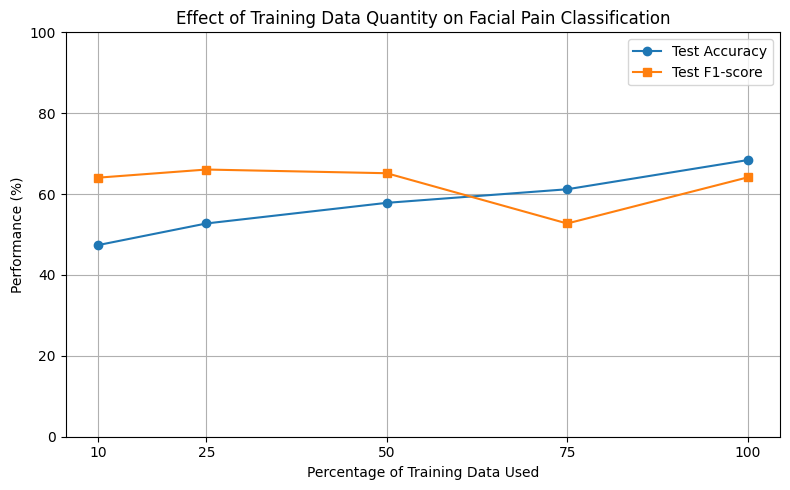

In [8]:
import matplotlib.pyplot as plt

df = results_v2.copy()

plt.figure(figsize=(8, 5))

plt.plot(
    df["training_fraction"] * 100,
    df["test_accuracy"] * 100,
    marker="o",
    label="Test Accuracy"
)

plt.plot(
    df["training_fraction"] * 100,
    df["test_f1"] * 100,
    marker="s",
    label="Test F1-score"
)

plt.xlabel("Percentage of Training Data Used")
plt.ylabel("Performance (%)")
plt.title("Effect of Training Data Quantity on Facial Pain Classification")

plt.xticks([10, 25, 50, 75, 100])
plt.ylim(0, 100)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import torch

print("Checking model and test data...")

print("Model available:", "model" in globals())
print("Test images available:", "X_test" in globals())
print("Test labels available:", "y_test" in globals())

if all(name in globals() for name in ["model", "X_test", "y_test"]):
    model.eval()

    with torch.no_grad():
        outputs = model(X_test)
        predictions = torch.argmax(outputs, dim=1)

    y_true = y_test.cpu().numpy()
    y_pred = predictions.cpu().numpy()

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print("\nUnique label values:", np.unique(y_true))
else:
    print("Some variables are missing. No training was performed.")

Checking model and test data...
Model available: False
Test images available: False
Test labels available: False
Some variables are missing. No training was performed.


In [10]:
from pathlib import Path

model_folder = ROOT / "04_Implementation" / "models"

print("Checking saved model files...\n")

for file in model_folder.rglob("*"):
    if file.is_file():
        print(file.name, "|", file.stat().st_size, "bytes")

Checking saved model files...

blaze_face_short_range.tflite | 229746 bytes
sam2_hiera_tiny.pt | 155906050 bytes


In [11]:
print("Model available:", "model" in globals())
print("Test images available:", "X_test" in globals())
print("Test labels available:", "y_test" in globals())

Model available: False
Test images available: False
Test labels available: False


In [13]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Facial Pain Assessment Research")

print("Project folders:\n")

for item in ROOT.iterdir():
    print(item.name)

print("\nSearching for train_manifest.csv...\n")

for file in ROOT.rglob("train_manifest.csv"):
    print(file)

Project folders:

00_Admin_and_Project
01_Literature_Review
02_Datasets
03_Research_Design
04_Implementation
05_Experiments
06_Results
07_Research_Paper
08_Presentations
09_Archive
manifests
right_portrait_crops
face_detection
segmentation_masks
reports
logs

Searching for train_manifest.csv...

/content/drive/MyDrive/Facial Pain Assessment Research/manifests/train_manifest.csv


In [14]:
import pandas as pd
from pathlib import Path

manifest_folder = Path("/content/drive/MyDrive/Facial Pain Assessment Research/manifests")

for name in ["train", "validation", "test"]:
    file_path = manifest_folder / f"{name}_manifest.csv"

    if file_path.exists():
        df = pd.read_csv(file_path)
        print(f"\n{name.upper()} SET")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print("Label counts:")
        print(df["label"].value_counts())
    else:
        print(f"\nMISSING: {file_path.name}")


TRAIN SET
Rows: 3748
Columns: ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
Label counts:
label
Pain      1942
NoPain    1806
Name: count, dtype: int64

VALIDATION SET
Rows: 803
Columns: ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
Label counts:
label
Pain      416
NoPain    387
Name: count, dtype: int64

TEST SET
Rows: 804
Columns: ['sample_id', 'repo_path', 'image_path', 'label', 'crop_path', 'filename_id']
Label counts:
label
NoPain    426
Pain      378
Name: count, dtype: int64


In [15]:
from pathlib import Path
import pandas as pd

M = ROOT / "manifests"

train = pd.read_csv(M / "train_manifest.csv")
val = pd.read_csv(M / "validation_manifest.csv")
test = pd.read_csv(M / "test_manifest.csv")

train_ids = set(train["filename_id"])
val_ids = set(val["filename_id"])
test_ids = set(test["filename_id"])

print("Train–Validation overlap:", len(train_ids & val_ids))
print("Train–Test overlap:", len(train_ids & test_ids))
print("Validation–Test overlap:", len(val_ids & test_ids))

Train–Validation overlap: 0
Train–Test overlap: 0
Validation–Test overlap: 0


In [16]:
from pathlib import Path
import pandas as pd

output = ROOT / "06_Results" / "split_verification.csv"
output.parent.mkdir(parents=True, exist_ok=True)

verification = pd.DataFrame({
    "check": [
        "Training images",
        "Validation images",
        "Test images",
        "Train-Validation filename_id overlap",
        "Train-Test filename_id overlap",
        "Validation-Test filename_id overlap"
    ],
    "result": [3748, 803, 804, 0, 0, 0]
})

verification.to_csv(output, index=False)

print("Saved:", output)
print(verification)

Saved: /content/drive/MyDrive/Facial Pain Assessment Research/06_Results/split_verification.csv
                                  check  result
0                       Training images    3748
1                     Validation images     803
2                           Test images     804
3  Train-Validation filename_id overlap       0
4        Train-Test filename_id overlap       0
5   Validation-Test filename_id overlap       0
